In [27]:
from scipy.stats import binom
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
def get_stat_power(N, mu_h0, mu_alternative, alpha):
    '''Вычисляет статистическую мощность критерия для биномиального распределения
    
    Параметры:
        N - количество бернуллиевских экспериментов (размер выборки)
        mu_h0 - вероятность успеха в нулевой гипотезе
        mu_alternative - предполагаемая вероятность успеха в эксперименте
        alpha - уровень значимости критерия
    '''
    binom_h0 = binom(n=N, p=mu_h0)
    binom_alternative = binom(n=N, p=mu_alternative)

    # вычисляем критическое значение
    critical_value = binom_h0.ppf(1 - alpha) + 1
    # вычисляем мощность по формуле
    return 1 - binom_alternative.cdf(critical_value - 1) 

In [23]:
n_grid = np.arange(10, 600, 10)
# можем вычислить 
power = get_stat_power(n_grid, 0.5, 0.6, alpha=0.05)

Зависимость мощности от числа экспериметнов

<>:2: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:2: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\ES\AppData\Local\Temp\ipykernel_11324\1049599887.py:2: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.title('Power for $\mu$ = 0.6', fontsize=12)


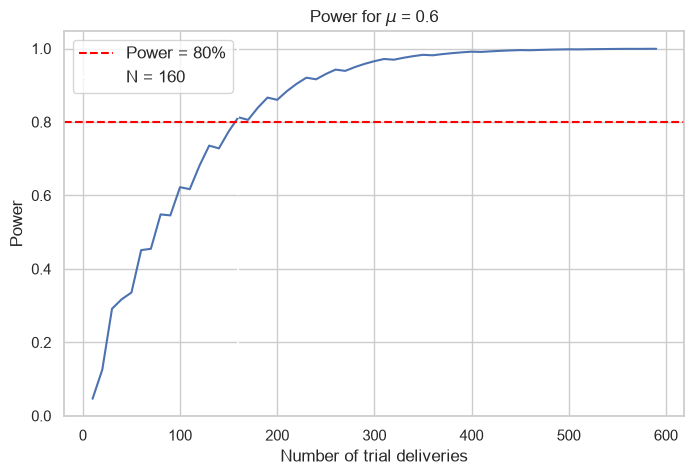

In [26]:
plt.figure(figsize=(8, 5))
plt.title('Power for $\mu$ = 0.6', fontsize=12)
plt.xlabel('Number of trial deliveries', fontsize=12)
plt.ylabel('Power', fontsize=12)

pwr = 0.8
plt.plot(n_grid, power)
plt.axhline(pwr, ls='--', color='red', label='Power = 80%')

# считаем минимальный размер выборки для мощности в 80% 
min_n = n_grid[power >= pwr].min()
plt.axvline(min_n, ls='--', color='white', label=f'N = {min_n}')

plt.legend(fontsize=12)
plt.show()

Зависимость $\mu$ от мощности

<>:5: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:5: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\ES\AppData\Local\Temp\ipykernel_11324\514457619.py:5: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel('$\mu$', fontsize=12)


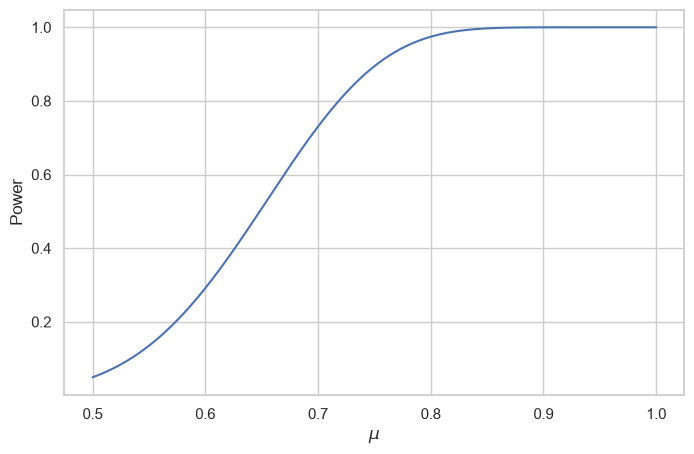

In [ ]:
mu_grid = np.linspace(0.5, 1, 500)
power = get_stat_power(30, 0.5, mu_grid, alpha=0.05)
plt.figure(figsize=(8, 5))
plt.xlabel('$\mu$', fontsize=12)
plt.ylabel('Power', fontsize=12)
plt.plot(mu_grid, power)
plt.show()

In [34]:
def binom_test_mde_one_sided(N, mu0, alpha=0.05, min_power=0.8):
    '''Вычисляет MDE одностороннего критерия для проверки гипотезы mu = mu0 в задаче с доставкой
    
    Параметры:
        N (int) - размер выборки
        mu0 (float) - вероятность успеха в нулевой гипотезе
        alpha (float) - уровень значимости критерия
        min_power (float) - желаемая мощность
        
    Возвращает:
        float - MDE'''
    delta_grid = np.linspace(0, 1 - mu0, 500) 
    power = get_stat_power(N, mu0, mu0 + delta_grid, alpha=alpha)
    # выберем подходящие delta и вернем первую
    fit_delta = delta_grid[power >= min_power]
    return fit_delta[0]

In [35]:
binom_test_mde_one_sided(30, 0.5)

np.float64(0.21843687374749496)